# [실습] 분류 — 확률을 예측하고 선을 긋기

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

# Chapter 3 실습. 1,000통으로 가입을 가장 많이 얻으려면?

**필수 머신러닝 · Chapter 3**

| Part | 주제 |
| --- | --- |
| Part 1 | 데이터와 친해지기 |
| Part 2 | 현행 방법 만들기: 사람이 쓰는 선정 규칙 |
| Part 3 | 모델과 임계값 |
| Part 4 | 통화 예산 곡선과 결정 |

## 분석 의뢰서

> **의뢰 부서**: 은행 마케팅팀
> **목적**: 정기예금 상품 가입을 권유하는 전화 캠페인을 하려 한다. 가입할 가능성이 높은 고객에게 먼저 전화하고 싶다.
> **제약**: 콜센터가 이번 캠페인에 걸 수 있는 전화는 약 1,000통이다. 고객은 9,000명이 넘는다.
> **질문**: 누구에게 전화해야 가입을 가장 많이 얻을 수 있을까?

## 이 실습의 질문

> **1,000통으로 가입을 가장 많이 얻으려면 누구에게 전화해야 하는가? 그리고 전화를 2,000통으로 늘리면 가입이 얼마나 늘어나는가?**

Chapter 1, 2와 같은 순서로 진행합니다. 여러분이 먼저 마케팅팀 담당자처럼 **사람이 쓰는 선정 규칙**을 만들고, 그 규칙과 모델을 **같은 평가용 데이터**에서 비교합니다. 마지막에는 마케팅팀에 보낼 보고 메모를 씁니다.

## 이 노트북을 쓰는 법

| 표시 | 뜻 |
| --- | --- |
| **[직접 작성]** | 빈 코드 셀을 직접 채웁니다. 강의 교안의 코드를 보지 않고 먼저 써 보세요 |
| **[판단]** | 코드가 아니라 생각을 적는 칸입니다. 셀을 더블클릭해 `나의 답:` 뒤에 적으세요 |
| **[제공]** | 미리 채워 둔 코드입니다. 읽고 실행하세요 |
| **힌트** | 막혔을 때만 펼치세요 |

## 준비

UCI Bank Marketing 데이터의 `bank-full.csv`(통화 45,211건)를 이 노트북과 같은 폴더에 두세요. 이 파일은 열을 쉼표가 아니라 세미콜론(`;`)으로 구분합니다.

In [1]:
# [제공] 이 실습에서 쓰는 라이브러리
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)

# 그래프의 한글 글꼴 (환경에 맞는 글꼴이 없으면 글자가 깨질 수 있습니다)
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

---
# Part 1. 데이터와 친해지기

## 1-1. 데이터 불러오기

**[직접 작성]** `bank-full.csv`를 불러와 `df`에 저장하고, 행과 열의 수와 처음 5행을 확인하세요.

<details><summary>힌트</summary>

구분자가 세미콜론이므로 `pd.read_csv("bank-full.csv", sep=";")`처럼 `sep`을 알려 줘야 합니다.
</details>

In [2]:
# 여기에 코드를 작성하세요
df = pd.read_csv("bank-full.csv", sep=";")   # 세미콜론(;)으로 구분된 파일
print(df.shape)                                 # (행 수, 열 수)
df.head()

(45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


원본 데이터에는 통화 시간(`duration`)이라는 열이 있습니다. 이 실습에서는 **쓰지 않습니다.** 이유는 Chapter 4에서 다룹니다. **[제공]** 셀을 실행해 이 열을 제외하세요.

In [3]:
# [제공] 통화 시간 열 제외
df = df.drop(columns=["duration"])
print(df.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


## 1-2. 맞히려는 값 만들기

결과 열 `y`는 "yes"/"no" 글자입니다. 모델이 다룰 수 있도록 0과 1로 바꿉니다.

**[직접 작성]** 가입(`yes`)이면 1, 아니면 0인 열 `target`을 `df`에 만들고, `target`의 값별 개수와 비율을 확인하세요.

<details><summary>힌트</summary>

`df["target"] = (df["y"] == "yes").astype(int)`, 비율은 `df["target"].value_counts(normalize=True)`.
</details>

In [4]:
# 여기에 코드를 작성하세요
df["target"] = (df["y"] == "yes").astype(int)   # yes → 1, no → 0
print(df["target"].value_counts())               # 값별 개수
print(df["target"].value_counts(normalize=True).round(3))   # 값별 비율

target
0    39922
1     5289
Name: count, dtype: int64
target
0    0.883
1    0.117
Name: proportion, dtype: float64


> **[판단]** "전부 미가입"이라고 답하는 방법의 정확도는 얼마인가요? 이 방법은 콜센터에 어떤 가치가 있을까요?
>
> 나의 답: 정확도는 **88.3%**입니다(미가입 비율 그대로). 숫자는 높아 보이지만 **가입할 고객을 한 명도 찾지 못하므로** 콜센터에는 아무 가치가 없습니다. 누구에게 전화할지 알려 주지 않기 때문입니다. 가입이 드문 문제에서는 정확도만 보면 속는다는 것을 보여 주는 기준선입니다.

## 1-3. 데이터의 결함 찾기

**[직접 작성]** 아래 두 가지를 확인하세요.

1. `pdays`(이전 캠페인 이후 경과일)가 `-1`인 행의 비율
2. 글자로 된 열마다 `"unknown"`이라는 값이 몇 개 있는지

<details><summary>힌트</summary>

비율은 `(df["pdays"] == -1).mean()`. `"unknown"`은 `df.select_dtypes("object")`로 글자 열만 고른 뒤 `(열 == "unknown").sum()`을 세면 됩니다. 글자 열이 아닌 `target` 같은 열은 건너뜁니다.
</details>

In [5]:
# 여기에 코드를 작성하세요
# 1. pdays가 -1인 행의 비율
print("pdays == -1 비율:", round((df["pdays"] == -1).mean(), 3))

# 2. 글자 열마다 "unknown" 개수 (y는 target과 같은 정보라 건너뜀)
text_cols = [c for c in df.columns if pd.api.types.is_string_dtype(df[c]) and c != "y"]
unknown = pd.Series({c: int((df[c] == "unknown").sum()) for c in text_cols})
print(unknown.sort_values(ascending=False))

pdays == -1 비율: 0.817
poutcome     36959
contact      13020
education     1857
job            288
marital          0
housing          0
default          0
loan             0
month            0
dtype: int64


> **[판단]** `pdays`의 −1은 어떤 뜻일까요? 이 열을 숫자 그대로 모델에 넣으면 어떤 문제가 생길까요?
>
> 나의 답: −1은 **이전 캠페인에서 한 번도 연락받은 적이 없는 고객**이라는 표시입니다(전체의 81.7%). 경과일이 아니라 "해당 없음"을 숫자로 적어 둔 것입니다.
> 숫자 그대로 넣으면 모델은 −1을 "0일보다 하루 더 최근"인 값으로 계산합니다. 그러면 "연락받은 적 없음"과 "어제 연락받음"이 비슷하다고 착각하게 됩니다. 성격이 다른 두 정보가 한 열에 섞인 셈입니다.
> → "이전 연락 여부(0/1)" 열을 따로 만들고, 경과일은 연락받은 고객에게만 쓰거나 구간으로 나누는 것이 좋습니다.

> **[판단]** `unknown`이 많은 열(`contact`, `poutcome`)은 어떻게 다루겠습니까? (예: 그대로 하나의 값으로 둔다 / 뺀다) 선택과 이유를 적으세요.
>
> 나의 답: **"unknown"을 하나의 값(범주)으로 그대로 둡니다.**
> - `poutcome`의 unknown(36,959건)은 대부분 이전 캠페인 대상이 아니었던 고객이라 그 자체가 의미 있는 정보입니다(pdays = −1과 같은 집단).
> - `contact`의 unknown은 가입률이 4.1%로 휴대전화(14.8%)보다 훨씬 낮습니다. "연락 수단이 기록되지 않은 고객"이라는 것 자체가 가입을 잘 구분해 줍니다.
> 열을 빼거나 그 행을 지우면 이 정보를 잃고, 데이터의 큰 부분(최대 82%)이 사라집니다.

## 1-4. 평가용 데이터 먼저 떼어 두기

Chapter 1, 2와 같은 원칙입니다. 이후의 탐색과 규칙 만들기는 **학습용 데이터만** 보고 하고, 평가용 데이터는 마지막 채점에만 씁니다.

**[직접 작성]** `df`를 학습용 80%, 평가용 20%로 나눠 `train_df`, `test_df`에 저장하세요. `random_state=42`, 그리고 가입 비율이 두 쪽에 같게 `target`으로 `stratify`합니다.

<details><summary>힌트</summary>

`train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["target"])`
</details>

In [6]:
# 여기에 코드를 작성하세요
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["target"])
print("학습용:", len(train_df), "| 평가용:", len(test_df))
print("가입 비율 - 학습용:", round(train_df["target"].mean(), 4), "| 평가용:", round(test_df["target"].mean(), 4))

학습용: 36168 | 평가용: 9043
가입 비율 - 학습용: 0.117 | 평가용: 0.117


> **[판단]** 왜 가입 비율이 두 쪽에 같도록(`stratify`) 나눌까요? 가입이 11.7%뿐인 데이터를 그냥 무작위로 나누면 어떤 일이 생길 수 있나요?
>
> 나의 답: 가입 고객이 11.7%뿐이라, 그냥 무작위로 나누면 우연히 한쪽에 가입 고객이 더 많이(또는 적게) 들어갈 수 있습니다. 그러면 학습용과 평가용의 문제 난이도가 달라지고, 평가 점수가 운에 따라 흔들립니다. `stratify`로 나누면 두 쪽 모두 가입 비율이 0.117로 같아져(실제 결과 확인) 공정하게 비교할 수 있습니다.

### 체크포인트

여기까지 막혀서 다음으로 넘어가지 못했다면 **아래 셀만 실행**하세요. 끝낸 사람은 실행하지 않아도 됩니다.

In [7]:
# [제공] 체크포인트: 1-4까지 끝낸 사람은 실행하지 않아도 됩니다
df = pd.read_csv("bank-full.csv", sep=";").drop(columns=["duration"])
df["target"] = (df["y"] == "yes").astype(int)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["target"])
print(len(train_df), len(test_df))

36168 9043


### 실습 도구 (실행만 하세요)

| 도구 | 하는 일 |
| --- | --- |
| `rate_by(열 이름)` | 학습용 데이터에서 그 열의 값별 가입률과 통화 수를 계산한다 (숫자 열은 `bins`로 구간을 나눈다) |
| `evaluate_selection(이름, 선정 여부)` | 평가용 데이터에서 선정한 고객 수와 그중 실제 가입 수를 보여 준다 |
| `make_data(피처 목록)` | 피처 목록으로 학습용·평가용 `X`, `y`를 만든다 |
| `record(이름, 피처, 확률)` | 모델의 점수(AUC, 상위 $N$명 가입 수)를 기록표에 남긴다 |
| `run_logistic(이름, 피처, ...)` | 로지스틱 회귀를 학습하고 점수를 기록한다 |

In [8]:
# [제공] 실습 도구
y_test = test_df["target"]
base_rate = y_test.mean()
experiment_log = []
probs = {}          # 실험 이름 → 평가용 데이터의 가입 확률

def rate_by(col, bins=None):
    """학습용 데이터에서 col의 값별 가입률과 통화 수를 계산합니다. 숫자 열은 bins로 구간을 나눕니다."""
    key = pd.cut(train_df[col], bins) if bins is not None else train_df[col]
    out = train_df.groupby(key, observed=True)["target"].agg(["mean", "size"])
    out.columns = ["가입률", "통화 수"]
    return out.round(3)

def evaluate_selection(name, mask):
    """평가용 데이터에서 선정한 고객(True)을 채점합니다. (선정 수, 그중 가입 수)를 돌려줍니다."""
    mask = pd.Series(np.asarray(mask), index=test_df.index)
    n_sel = int(mask.sum()); hits = int(y_test[mask].sum()); total = int(y_test.sum())
    print(f"[{name}] 선정 {n_sel:,}명 | 그중 실제 가입 {hits}명 ({hits / n_sel * 100:.1f}%) | "
          f"무작위로 {n_sel:,}명을 골랐다면 약 {n_sel * base_rate:.0f}명 | 전체 가입 고객 {total}명 중 {hits / total * 100:.1f}%를 찾음")
    return n_sel, hits

def make_data(features):
    X = pd.get_dummies(df[features]).astype(float)
    return X.loc[train_df.index], X.loc[test_df.index], train_df["target"], test_df["target"]

def summarize(prob):
    prob = np.asarray(prob)
    ys = y_test.values[np.argsort(-prob, kind="stable")]
    return {"ROC AUC": roc_auc_score(y_test, prob), "PR AUC": average_precision_score(y_test, prob),
            "상위 1,000명 가입": int(ys[:1000].sum()), "상위 2,000명 가입": int(ys[:2000].sum())}

def record(name, features, prob):
    s = summarize(prob)
    experiment_log.append({"실험": name, "피처 수": len(features),
                           "ROC AUC": round(s["ROC AUC"], 3), "PR AUC": round(s["PR AUC"], 3),
                           "상위 1,000명 가입": s["상위 1,000명 가입"], "상위 2,000명 가입": s["상위 2,000명 가입"]})
    probs[name] = np.asarray(prob)
    print(f"기록: [{name}] ROC AUC {s['ROC AUC']:.3f} | PR AUC {s['PR AUC']:.3f} | 상위 1,000명 중 가입 {s['상위 1,000명 가입']}명")

def run_logistic(name, features, **model_kwargs):
    """피처 목록으로 로지스틱 회귀를 학습하고(스케일링 포함) 점수를 기록합니다."""
    X_tr, X_te, y_tr, _ = make_data(features)
    scaler = StandardScaler().fit(X_tr)
    model = LogisticRegression(max_iter=3000, **model_kwargs).fit(scaler.transform(X_tr), y_tr)
    prob = model.predict_proba(scaler.transform(X_te))[:, 1]
    record(name, features, prob)

## 1-5. 가입률이 높은 집단 찾기

학습용 데이터에서 "어떤 고객이 많이 가입하는가"를 찾아봅니다. 이 관찰이 Part 2에서 규칙의 재료가 됩니다. 전체 가입률은 11.7%입니다.

**[직접 작성]** `rate_by`로 다음을 확인하세요. 결과의 **통화 수**도 함께 봅니다.

- `poutcome`(이전 캠페인 결과), `contact`(연락 수단), `housing`(주택 대출), `month`(통화 월) 중 **세 개 이상**
- 나이는 구간으로: `rate_by("age", bins=[17, 25, 35, 45, 55, 65, 100])`

<details><summary>힌트</summary>

한 줄에 하나씩 `print(rate_by("열 이름"))`을 쓰세요. 결과를 가입률 순으로 보려면 `.sort_values("가입률", ascending=False)`를 붙입니다.
</details>

In [9]:
# 여기에 코드를 작성하세요
for col in ["poutcome", "contact", "housing", "month"]:
    print(f"--- {col}")
    print(rate_by(col).sort_values("가입률", ascending=False))
    print()
print("--- age (구간)")
print(rate_by("age", bins=[17, 25, 35, 45, 55, 65, 100]))

--- poutcome
            가입률   통화 수
poutcome              
success   0.646   1205
other     0.165   1485
failure   0.123   3889
unknown   0.092  29589

--- contact
             가입률   통화 수
contact                
cellular   0.148  23465
telephone  0.139   2317
unknown    0.041  10386

--- housing
           가입률   통화 수
housing              
no       0.167  15986
yes      0.077  20182

--- month
         가입률   통화 수
month              
mar    0.509    391
dec    0.472    178
sep    0.452    451
oct    0.438    592
apr    0.195   2394
feb    0.168   2078
aug    0.109   4986
jun    0.104   4237
jan    0.102   1119
nov    0.101   3143
jul    0.093   5537
may    0.067  11062

--- age (구간)
             가입률   통화 수
age                    
(17, 25]   0.244   1079
(25, 35]   0.119  12511
(35, 45]   0.095  11098
(45, 55]   0.092   7589
(55, 65]   0.141   3282
(65, 100]  0.427    609


> **[판단]** 가입률이 전체 평균(11.7%)보다 눈에 띄게 높은 집단을 두 개 이상 적어 보세요. (예: "○○인 고객은 가입률 △△%")
>
> 나의 답: - **이전 캠페인 성공(poutcome = success)**인 고객은 가입률 **64.6%** (1,205건) → 평균의 5배 이상
> - **65세 초과** 고객은 가입률 **42.7%** (609건), **25세 이하**는 **24.4%** (1,079건)
> - **3월·12월·9월·10월**에 통화한 고객은 가입률 **44~51%** (각 178~592건)
> - 주택 대출 없음 16.7%, 휴대전화 연락 14.8% → 평균보다 조금 높지만 인원이 많음

> **[판단]** 3월의 가입률은 매우 높지만 통화 수는 매우 적습니다. 통화 수가 적은 집단의 가입률을 얼마나 믿을 수 있을까요? 규칙의 근거로 쓸 때 어떤 점을 조심해야 하나요?
>
> 나의 답: 통화 수가 적으면 **우연의 영향이 큽니다.** 3월은 391건뿐이라 몇 명만 달라져도 가입률이 크게 바뀝니다(대략 ±5%p 정도 흔들릴 수 있음). 12월은 178건으로 더 적습니다.
> 또 "3월"은 고객의 특징이 아니라 **은행이 그때 어떤 캠페인을 했는지**를 반영할 수 있습니다(예: 3월에는 소수의 유망 고객에게만 전화했을 수 있음). 그래서 규칙의 근거로 쓸 때는
> 1. 통화 수가 충분한 집단을 우선하고
> 2. 다음 캠페인에서도 같은 일이 반복될 이유가 있는지 확인해야 합니다.

---
# Part 2. 현행 방법 만들기: 사람이 쓰는 선정 규칙

여러분이 마케팅팀 담당자라고 생각해 보세요. 머신러닝 없이, 전화할 고객을 고르는 **규칙 하나**를 만들어 봅시다. 강의 Part 2에서 본 것처럼, 규칙은 "이 조건에 맞는 고객"을 고를 뿐 순위를 매기지는 못합니다. 그 한계가 실제로 무엇인지 직접 확인합니다.

## 규칙을 만들 때의 약속

- 조건은 **두세 개를 넘기지 않습니다.**
- 근거는 **1-5에서 본 집계**입니다. 평가용 데이터를 보고 규칙을 고치지 않습니다.
- 규칙은 "이 조건에 맞는 고객에게 전화한다"입니다.

## 2-1. 나의 규칙 만들기

> **[판단]** 나의 규칙(말로): 만약 ______ 이면 전화한다.
>
> 이 조건을 고른 근거(1-5의 어떤 집계인가):
>
> 나의 답: 나의 규칙(말로): 만약 **이전 캠페인에서 가입했거나(poutcome = success), 60세를 넘으면** 전화한다.
>
> 이 조건을 고른 근거:
> - 1-5에서 이전 캠페인 성공 고객의 가입률은 64.6%(1,205건)로 가장 높았습니다.
> - 65세 초과는 42.7%(609건)로 높았습니다.
> - 두 집단 모두 통화 수가 수백~천 건이라 3월처럼 표본이 너무 적지 않습니다. 월은 고객의 특징이 아니라 캠페인 시기라서 첫 규칙에서는 뺐습니다.

**[직접 작성]** 규칙을 코드로 옮겨 평가용 고객 중 선정할 고객을 `True`/`False`로 표시한 `selected`를 만드세요. 그다음 `evaluate_selection`으로 채점하고, 결과를 `rule_n, rule_hits`에 저장하세요.

<details><summary>힌트</summary>

조건은 `&`(그리고), `|`(또는)로 묶고, 조건마다 괄호를 칩니다.

```python
selected = (test_df["contact"] == "cellular") & (test_df["housing"] == "no")
rule_n, rule_hits = evaluate_selection("내 규칙", selected)
```

이 예시는 형식만 보여 주는 것입니다. 여러분의 규칙을 쓰세요.
</details>

In [10]:
# 여기에 코드를 작성하세요
# 선정 결과는 selected, 채점 결과는 rule_n, rule_hits라는 이름으로 저장하세요 (Part 4에서 다시 씁니다)
# 나의 규칙: 이전 캠페인이 성공했거나, 60세를 넘으면 전화한다
selected = (test_df["poutcome"] == "success") | (test_df["age"] > 60)
rule_n, rule_hits = evaluate_selection("내 규칙", selected)

[내 규칙] 선정 484명 | 그중 실제 가입 265명 (54.8%) | 무작위로 484명을 골랐다면 약 57명 | 전체 가입 고객 1058명 중 25.0%를 찾음


> **[판단]** 내 규칙은 무작위로 같은 수의 고객을 골랐을 때보다 가입을 몇 배 더 얻었나요? 선정한 고객 수는 콜센터의 1,000통과 비교해 어떤가요?
>
> 나의 답: 484명을 골라 **265명이 가입**(54.8%)했습니다. 무작위로 484명을 고르면 약 57명이므로 **약 4.6배**입니다.
> 하지만 고른 인원이 484명으로 **1,000통의 절반도 안 됩니다.** 나머지 500여 통은 누구에게 걸지 이 규칙으로는 정할 수 없습니다.

## 2-2. 규칙을 넓혀 1,000통을 채워 보기

콜센터는 약 1,000통을 걸 수 있습니다. 내 규칙이 고른 고객이 1,000명보다 훨씬 적다면 남는 전화는 어떻게 쓸까요? 조건을 **하나 완화**해 선정 고객을 약 1,000~2,000명으로 늘려 보세요.

**[직접 작성]** 규칙을 느슨하게 바꾼 `selected_wide`를 만들어 `evaluate_selection`으로 채점하고, 결과를 `wide_n, wide_hits`에 저장하세요. (이미 1,000명 이상을 고르는 규칙이라면 조건을 하나 추가해 줄여 보세요.)

<details><summary>힌트</summary>

예를 들어 `|`(또는)로 조건을 하나 더하면 선정이 늘고, `&`(그리고)로 조건을 하나 더하면 줄어듭니다. 나이 기준을 넓히거나, 월을 몇 개 더 포함하는 식으로 바꿔 보세요.
</details>

In [11]:
# 여기에 코드를 작성하세요
# 결과는 selected_wide, wide_n, wide_hits라는 이름으로 저장하세요
# 넓힌 규칙: 내 규칙 또는 (휴대전화 연락 그리고 주택 대출 없음 그리고 가입률이 높은 6개 월)
good_months = ["mar", "dec", "sep", "oct", "apr", "feb"]   # 1-5에서 가입률이 전체 평균보다 높았던 월
selected_wide = selected | ((test_df["contact"] == "cellular") & (test_df["housing"] == "no")
                            & test_df["month"].isin(good_months))
wide_n, wide_hits = evaluate_selection("내 규칙(넓힘)", selected_wide)

[내 규칙(넓힘)] 선정 1,017명 | 그중 실제 가입 430명 (42.3%) | 무작위로 1,017명을 골랐다면 약 119명 | 전체 가입 고객 1058명 중 40.6%를 찾음


> **[판단]** 규칙을 넓히자 선정 고객 수와 가입률이 어떻게 변했나요? "가입 가능성이 높은 순서대로 1,000명"을 규칙만으로 고를 수 있을까요? 못 한다면 이유는 무엇인가요?
>
> 나의 답: 선정 인원은 484명 → **1,017명**으로 늘고 가입도 265명 → **430명**으로 늘었습니다. 하지만 가입률은 54.8% → **42.3%**로 떨어졌습니다. 새로 추가된 고객들이 원래 고객보다 덜 유망하기 때문입니다.
> 규칙만으로는 "가능성이 높은 순서대로 1,000명"을 고를 수 **없습니다**. 규칙은 조건에 맞으면 "예", 아니면 "아니오"로만 나누기 때문입니다. 조건에 맞는 고객끼리는 누가 더 유망한지 순서가 없습니다. 그래서 인원을 정확히 1,000명에 맞추려면 조건을 손으로 계속 바꿔 가며 맞춰야 합니다.

---
# Part 3. 모델과 임계값

이제 모델이 **확률로 순위를 매기게** 해 봅니다. 강의 Part 1의 코드를 보지 말고 먼저 직접 써 보세요.

## 3-1. 첫 모델: 로지스틱 회귀

**[제공]** 강의에서 쓴 기본 피처 목록입니다.

In [12]:
# [제공] 기본 피처 목록 (통화 시간은 제외)
base_features = ["age", "balance", "campaign", "previous", "poutcome", "housing",
                 "loan", "contact", "month", "job", "marital", "education"]

**[직접 작성]** 아래 순서로 작성하세요.

1. `make_data(base_features)`로 `X_train, X_test, y_train, y_test`를 만든다
2. `StandardScaler`를 학습용 데이터로 학습(`fit`)하고, 학습용과 평가용에 적용(`transform`)한다
3. `LogisticRegression(max_iter=2000)`을 학습한다
4. 평가용 고객의 **가입 확률**을 `prob`에 저장한다 (`predict_proba`의 두 번째 열)

<details><summary>힌트</summary>

강의 1-6과 같은 순서입니다. 확률은 `model.predict_proba(X_test_scaled)[:, 1]`입니다.
</details>

In [13]:
# 여기에 코드를 작성하세요
# 1. 데이터 만들기
X_train, X_test, y_train, y_test = make_data(base_features)

# 2. 스케일링: 학습용으로만 fit, 학습용·평가용 둘 다 transform
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. 로지스틱 회귀 학습
model = LogisticRegression(max_iter=2000).fit(X_train_scaled, y_train)

# 4. 평가용 고객의 가입 확률 (두 번째 열 = 가입(1)일 확률)
prob = model.predict_proba(X_test_scaled)[:, 1]
print("피처 수(원핫 후):", X_train.shape[1])
print("확률 예시:", prob[:5].round(3))

피처 수(원핫 후): 46
확률 예시: [0.014 0.024 0.035 0.017 0.133]


## 3-2. 정확도는 속인다

**[직접 작성]** 임계값 0.5로 가입 여부를 예측했을 때(`pred = (prob >= 0.5).astype(int)`) 아래를 계산해 출력하세요.

- 정확도, 그리고 "전부 미가입" 베이스라인의 정확도
- 혼동행렬
- 정밀도와 재현율

<details><summary>힌트</summary>

정확도는 `(pred == y_test).mean()`, 베이스라인은 `(y_test == 0).mean()`. 나머지는 `confusion_matrix(y_test, pred)`, `precision_score(y_test, pred)`, `recall_score(y_test, pred)`입니다.
</details>

In [14]:
# 여기에 코드를 작성하세요
pred = (prob >= 0.5).astype(int)
print("정확도:", round((pred == y_test).mean(), 4))
print("'전부 미가입' 베이스라인 정확도:", round((y_test == 0).mean(), 4))
print("혼동행렬 [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test, pred))
print("정밀도:", round(precision_score(y_test, pred), 3))
print("재현율:", round(recall_score(y_test, pred), 3))

정확도: 0.8933
'전부 미가입' 베이스라인 정확도: 0.883
혼동행렬 [[TN, FP], [FN, TP]]:
[[7886   99]
 [ 866  192]]
정밀도: 0.66
재현율: 0.181


> **[판단]** 정확도는 베이스라인보다 얼마나 높은가요? 그런데 가입할 고객 중 모델이 찾아낸 비율(재현율)은 얼마인가요? 두 숫자가 이렇게 다른 이유를 설명해 보세요.
>
> 나의 답: 정확도는 **89.3%**로 베이스라인(88.3%)보다 겨우 **1.0%p** 높습니다. 그런데 재현율은 **18.1%**입니다. 실제 가입 고객 1,058명 중 192명만 찾고 866명은 놓쳤습니다.
> 이유: 가입 고객이 11.7%뿐이라 모델이 대부분을 "미가입"으로 예측해도 정확도는 높게 나옵니다. 또 가입 확률이 50%를 넘는 고객은 드물어서, 임계값 0.5에서는 "가입"으로 예측하는 고객이 291명뿐입니다. 정확도는 많은 쪽(미가입)을 맞히는 데 좌우되고, 재현율은 적은 쪽(가입)을 얼마나 찾았는지만 봅니다.

## 3-3. 임계값을 움직이면

**[직접 작성]** 임계값을 `[0.5, 0.4, 0.3, 0.2, 0.15, 0.1, 0.05]`로 바꿔 가며, 임계값마다 다음을 계산해 하나의 표(`DataFrame`)로 출력하세요.

- 가입으로 예측한 고객 수
- TP(찾은 가입), FP(헛걸음), FN(놓친 가입)
- 정밀도, 재현율

<details><summary>힌트</summary>

```python
rows = []
for t in [0.5, 0.4, ...]:
    pred = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"임계값": t, "예측 가입 수": pred.sum(), "TP": tp, "FP": fp, "FN": fn,
                 "정밀도": round(tp / (tp + fp), 3), "재현율": round(tp / (tp + fn), 3)})
pd.DataFrame(rows)
```
</details>

In [15]:
# 여기에 코드를 작성하세요
rows = []
for t in [0.5, 0.4, 0.3, 0.2, 0.15, 0.1, 0.05]:
    pred = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"임계값": t, "예측 가입 수": int(pred.sum()), "TP": tp, "FP": fp, "FN": fn,
                 "정밀도": round(tp / (tp + fp), 3), "재현율": round(tp / (tp + fn), 3)})
pd.DataFrame(rows)

,임계값,예측 가입 수,TP,FP,FN,정밀도,재현율
0,0.50,291,192,99,866,0.660,0.181
1,0.40,443,263,180,795,0.594,0.249
2,0.30,627,347,280,711,0.553,0.328
3,0.20,1016,466,550,592,0.459,0.440
4,0.15,1596,563,1033,495,0.353,0.532
5,0.10,3440,763,2677,295,0.222,0.721
6,0.05,6650,981,5669,77,0.148,0.927


> **[판단]** 콜센터가 약 1,000통을 걸 수 있다면, 임계값을 대략 얼마로 잡으면 "가입으로 예측한 고객"이 1,000명 안팎이 되나요? 그때 정밀도와 재현율은 얼마인가요?
>
> 나의 답: 임계값을 **0.2**로 잡으면 "가입으로 예측한 고객"이 **1,016명**으로 1,000명 안팎이 됩니다. 이때 **정밀도 45.9%**(전화 2통 중 약 1통이 가입), **재현율 44.0%**(가입 고객 1,058명 중 466명을 찾음)입니다.

> **[판단]** 전화 한 통의 비용과 가입 한 건의 가치가 모두 정해져 있다면, 임계값은 어떻게 정해야 할까요? 1,000통이라는 제약이 있을 때는 임계값을 따로 고민할 필요가 있을까요?
>
> 나의 답: 비용과 가치가 정해져 있으면 **"이 고객에게 전화해서 얻는 기대 가치 ≥ 전화 비용"**일 때 전화합니다. 즉 `가입 확률 × 가입 가치 ≥ 통화 비용`이므로 임계값 = 통화 비용 ÷ 가입 가치입니다. (예: 10달러 ÷ 100달러 = 0.1)
> 1,000통 제약이 있으면 임계값을 따로 고민할 필요가 거의 없습니다. **확률 높은 순서로 1,000명에게 전화**하면 되고, 임계값은 "1,000번째 고객의 확률"로 저절로 정해집니다(약 0.2). 다만 그 1,000번째 고객의 확률이 비용 기준(0.1)보다도 높다면 "예산을 늘리면 더 이득"이라는 신호가 됩니다.

## 3-4. 피처와 설정을 바꿔 보기

모델의 점수를 임계값 하나가 아니라 **임계값과 무관한 지표**로 비교합니다. 아래 `record`는 다음을 기록표에 남깁니다.

- ROC AUC, PR AUC
- 확률이 높은 순서로 1,000명(또는 2,000명)에게 전화했을 때 실제 가입한 수

**[직접 작성]** 3-1의 첫 모델을 `record("기본 모델", base_features, prob)`로 기록하세요.

In [16]:
# 여기에 코드를 작성하세요
record("기본 모델", base_features, prob)

기록: [기본 모델] ROC AUC 0.773 | PR AUC 0.411 | 상위 1,000명 중 가입 464명


**[직접 작성]** 이제 `run_logistic(이름, 피처 목록, ...)`으로 **세 번 이상** 실험하세요. 매번 점수가 자동으로 기록됩니다.

<details><summary>힌트</summary>

```python
run_logistic("월 제외", [f for f in base_features if f != "month"])
run_logistic("피처 추가", base_features + ["default", "day", "pdays"])
run_logistic("가중치 균형", base_features, class_weight="balanced")
run_logistic("규제 강화", base_features, C=0.01)
```

`C`는 작을수록 모델을 단순하게 만드는 설정입니다.
</details>

In [17]:
# 실험 1: 월(month) 빼기
run_logistic("월 제외", [f for f in base_features if f != "month"])

# 실험 2: 피처 추가 (default, day, pdays)
run_logistic("피처 추가", base_features + ["default", "day", "pdays"])

# 실험 3: 가입 고객에 가중치를 더 주기
run_logistic("가중치 균형", base_features, class_weight="balanced")

# 실험 4: 규제 강화 (모델을 더 단순하게)
run_logistic("규제 강화", base_features, C=0.01)

기록: [월 제외] ROC AUC 0.754 | PR AUC 0.367 | 상위 1,000명 중 가입 403명


기록: [피처 추가] ROC AUC 0.772 | PR AUC 0.411 | 상위 1,000명 중 가입 466명


기록: [가중치 균형] ROC AUC 0.773 | PR AUC 0.409 | 상위 1,000명 중 가입 461명
기록: [규제 강화] ROC AUC 0.773 | PR AUC 0.411 | 상위 1,000명 중 가입 468명


**[제공]** 실험 기록표를 상위 1,000명 가입 수 순으로 봅니다.

In [18]:
# [제공] 실험 기록표
pd.DataFrame(experiment_log).sort_values("상위 1,000명 가입", ascending=False, kind="stable")

,실험,피처 수,ROC AUC,PR AUC,"상위 1,000명 가입","상위 2,000명 가입"
4,규제 강화,12,0.773,0.411,468,611
2,피처 추가,15,0.772,0.411,466,612
0,기본 모델,12,0.773,0.411,464,612
3,가중치 균형,12,0.773,0.409,461,613
1,월 제외,11,0.754,0.367,403,560


> **[판단]** 어떤 실험에서 점수가 가장 크게 변했나요? 반대로 피처를 더하거나 설정을 바꿔도 거의 변하지 않은 실험은 무엇인가요? 거의 변하지 않았다는 것은 무엇을 뜻할까요?
>
> 나의 답: 가장 크게 변한 것은 **"월 제외"**입니다. 상위 1,000명 가입이 464명 → **403명**(−61명), ROC AUC 0.773 → 0.754로 떨어졌습니다.
> 반대로 "피처 추가", "가중치 균형", "규제 강화"는 상위 1,000명 가입이 461~468명으로 **거의 변하지 않았습니다.**
> 거의 변하지 않았다는 것은 다음을 뜻합니다.
> 1. 더한 피처(default, day, pdays)에 **새로운 정보가 거의 없다**. pdays는 이미 poutcome·previous와 겹칩니다.
> 2. 가중치나 규제를 바꿔도 **고객의 순서는 거의 그대로**다. 확률의 크기만 달라질 뿐입니다.
> 3. 2~4명 차이는 우연 수준이라, 어느 것이 더 좋다고 말하기 어렵다.

> **[판단]** 월(`month`)을 빼면 점수가 떨어졌습니다. 월이 가입을 설명하는 이유로 무엇을 생각할 수 있나요? 이 변수를 모델에 쓸 때 조심할 점은 무엇일까요?
>
> 나의 답: 월이 가입을 설명하는 이유로 생각할 수 있는 것:
> - 은행이 **언제, 몇 명에게** 캠페인을 했는지가 반영됩니다. 5월에는 11,062건을 대량으로 걸어 가입률이 6.7%로 낮고, 3·9·10·12월에는 적은 수의 유망 고객에게만 건 것으로 보입니다.
> - 계절에 따라 금리나 보너스 시기 같은 사정이 다를 수 있습니다.
>
> 조심할 점:
> - 월은 고객의 특징이 아니라 **과거 캠페인 운영 방식**입니다. 다음 캠페인을 3월에 한다고 가입률이 50%가 되리라는 보장이 없습니다.
> - 다음 캠페인은 보통 한 달에 진행하므로, 같은 캠페인 안에서는 월로 고객을 구분할 수 없습니다.
> - 2008~2010년 금융위기 시기의 특수한 패턴일 수 있습니다.

> **[판단]** 모델을 고를 때 ROC AUC, PR AUC, "상위 1,000명 가입 수" 중 무엇을 기준으로 삼겠습니까? 이번 의뢰서에서는 어느 쪽이 가장 직접적인가요?
>
> 나의 답: 이번 의뢰서에서는 **"상위 1,000명 가입 수"**가 가장 직접적입니다. 질문 자체가 "1,000통으로 가입을 가장 많이 얻으려면?"이기 때문입니다.
> - PR AUC는 가입이 드문 문제에서 상위권을 얼마나 잘 맞히는지 보여 주므로 보조 지표로 좋습니다.
> - ROC AUC는 전체 순서를 고르게 보기 때문에, 1,000통처럼 **상위 일부만 쓰는 상황**과는 거리가 있습니다.
> 그래서 상위 1,000명 가입 수로 고르고, 차이가 작으면 PR AUC를 함께 봅니다.

---
# Part 4. 통화 예산 곡선과 결정

이제 질문으로 돌아옵니다. **1,000통으로 가입을 가장 많이 얻으려면 누구에게 전화해야 하는가? 전화를 2,000통으로 늘리면 가입이 얼마나 늘어나는가?**

## 4-1. 상위 $N$명 표 만들기

**[직접 작성]** 3-4의 기록표에서 "상위 1,000명 가입"이 가장 많은 실험을 골라 그 이름을 `best_name`에 저장하고, 그 확률을 `best_prob`에 저장하세요. 그다음 확률이 높은 순서로 고객을 정렬해, 평가용 고객의 실제 가입 여부를 그 순서대로 늘어놓은 `y_sorted`를 만드세요.

<details><summary>힌트</summary>

각 실험의 확률은 `probs`에 이름으로 저장되어 있습니다. `best_name = "기본 모델"`처럼 이름을 적고 `best_prob = probs[best_name]`로 꺼냅니다.

정렬 순서는 `order = np.argsort(-best_prob)`, 정렬된 가입 여부는 `y_sorted = y_test.values[order]`.
</details>

In [19]:
# 여기에 코드를 작성하세요
log_table = pd.DataFrame(experiment_log).sort_values("상위 1,000명 가입", ascending=False, kind="stable")
best_name = log_table.iloc[0]["실험"]       # 상위 1,000명 가입이 가장 많은 실험
best_prob = probs[best_name]
order = np.argsort(-best_prob, kind="stable")   # 확률이 높은 순서
y_sorted = y_test.values[order]                  # 그 순서대로 늘어놓은 실제 가입 여부
print("선택한 실험:", best_name)
print("확률 상위 10명의 실제 가입 여부:", y_sorted[:10])

선택한 실험: 규제 강화
확률 상위 10명의 실제 가입 여부: [0 1 1 1 0 1 1 1 1 1]


**[직접 작성]** 전화 수 $N$이 500, 1,000, 2,000, 3,000일 때 각각

- 확률 상위 $N$명 중 실제 가입 수
- 가입률
- 무작위로 $N$명을 골랐을 때의 기대 가입 수와 모델이 몇 배 더 얻는지

를 표로 출력하세요.

<details><summary>힌트</summary>

`y_sorted[:N].sum()`이 상위 $N$명 중 가입 수입니다. 무작위 기대 가입 수는 `N * base_rate`입니다. (`base_rate`는 도구 셀에서 만들어 둔 전체 가입률입니다.)
</details>

In [20]:
# 여기에 코드를 작성하세요
rows = []
for N in [500, 1000, 2000, 3000]:
    hits = int(y_sorted[:N].sum())
    random_hits = N * base_rate
    rows.append({"전화 수 N": N, "모델 가입 수": hits, "가입률": round(hits / N, 3),
                 "무작위 기대 가입 수": round(random_hits, 1), "무작위 대비 몇 배": round(hits / random_hits, 2)})
pd.DataFrame(rows)

,전화 수 N,모델 가입 수,가입률,무작위 기대 가입 수,무작위 대비 몇 배
0,500,290,0.580,58.5,4.96
1,1000,468,0.468,117.0,4.00
2,2000,611,0.305,234.0,2.61
3,3000,720,0.240,351.0,2.05


## 4-2. 예산 곡선 그리기

**[직접 작성]** 상위 몇 명까지 전화했을 때 **누적 가입 수**가 얼마인지를 `cum_model`에 저장하세요. (`y_sorted`를 누적해서 더한 값입니다.)

<details><summary>힌트</summary>

`cum_model = np.cumsum(y_sorted)`. `cum_model[999]`가 1,000통을 걸었을 때의 가입 수입니다. (순서는 0부터 세므로 1,000번째는 999번입니다.)
</details>

In [21]:
# 여기에 코드를 작성하세요
cum_model = np.cumsum(y_sorted)
print("1,000통을 걸었을 때 가입 수:", cum_model[999])
print("2,000통을 걸었을 때 가입 수:", cum_model[1999])

1,000통을 걸었을 때 가입 수: 468
2,000통을 걸었을 때 가입 수: 611


**[제공]** 모델의 곡선과 무작위, 그리고 Part 2의 내 규칙(두 점)을 한 그래프에 그립니다.

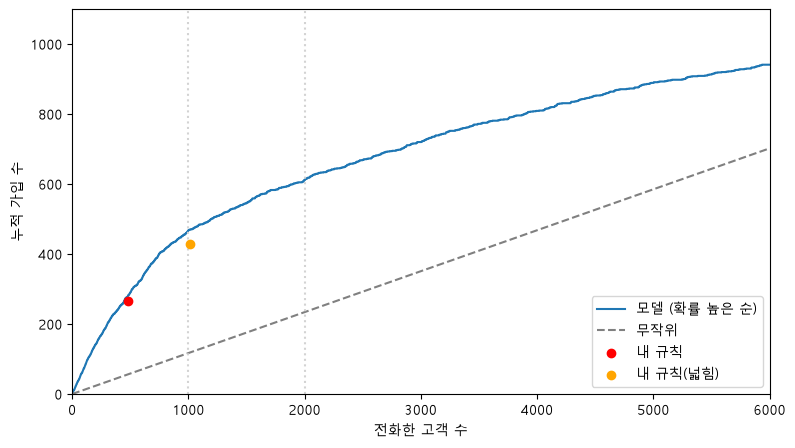

In [22]:
# [제공] 통화 예산 곡선
N_all = len(y_sorted)
x = np.arange(1, N_all + 1)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x, cum_model, label="모델 (확률 높은 순)")
ax.plot(x, x * base_rate, linestyle="--", color="gray", label="무작위")
ax.scatter([rule_n], [rule_hits], color="red", zorder=5, label="내 규칙")
ax.scatter([wide_n], [wide_hits], color="orange", zorder=5, label="내 규칙(넓힘)")
for N in (1000, 2000):
    ax.axvline(N, color="lightgray", linestyle=":")
ax.set_xlim(0, 6000)
ax.set_ylim(0, 1100)
ax.set_xlabel("전화한 고객 수")
ax.set_ylabel("누적 가입 수")
ax.legend()
plt.show()

> **[판단]** 내 규칙의 두 점은 모델의 곡선과 비교해 어디에 있나요? 규칙을 넓혔을 때 점이 곡선에서 멀어졌나요, 가까워졌나요?
>
> 나의 답: 두 점 모두 **모델 곡선보다 조금 아래**에 있습니다(규칙이 모델보다 조금 못함).
> - 내 규칙: 484명에 265명. 모델은 같은 인원에 283명입니다.
> - 넓힌 규칙: 1,017명에 430명. 모델은 같은 인원에 470명입니다.
> 넓혔을 때 곡선과의 간격이 18명 → 40명으로 **멀어졌습니다.** 규칙을 넓힐수록 덜 유망한 고객이 순서 없이 한꺼번에 들어오기 때문입니다.

## 4-3. 같은 수를 고른다면

규칙과 모델을 공정하게 비교하려면 **같은 수의 고객**을 골라야 합니다. 규칙이 `rule_n`명을 골랐다면, 모델도 상위 `rule_n`명만 고르면 됩니다.

**[직접 작성]** 모델이 확률 상위 `rule_n`명, 그리고 `wide_n`명을 골랐을 때 얻는 가입 수를 `model_at_rule`, `model_at_wide`에 저장하고, 규칙의 가입 수(`rule_hits`, `wide_hits`)와 나란히 출력하세요.

<details><summary>힌트</summary>

`cum_model[rule_n - 1]`입니다. ($N$명을 골랐을 때의 가입 수는 `cum_model`의 $N$번째 값입니다.)
</details>

In [23]:
# 여기에 코드를 작성하세요
model_at_rule = int(cum_model[rule_n - 1])
model_at_wide = int(cum_model[wide_n - 1])
pd.DataFrame({
    "선정 인원": [rule_n, wide_n],
    "규칙 가입": [rule_hits, wide_hits],
    "모델 가입 (같은 인원)": [model_at_rule, model_at_wide],
    "모델 - 규칙": [model_at_rule - rule_hits, model_at_wide - wide_hits],
    "모델 / 규칙 (배)": [round(model_at_rule / rule_hits, 2), round(model_at_wide / wide_hits, 2)],
}, index=["내 규칙", "내 규칙(넓힘)"])

,선정 인원,규칙 가입,모델 가입 (같은 인원),모델 - 규칙,모델 / 규칙 (배)
내 규칙,484,265,283,18,1.07
내 규칙(넓힘),1017,430,470,40,1.09


> **[판단]** 같은 수의 고객을 골랐을 때 모델이 내 규칙보다 가입을 몇 명 더(몇 배) 얻었나요? 규칙을 넓혔을 때 그 차이는 어떻게 달라졌나요?
>
> 나의 답: - 내 규칙(484명): 모델이 **18명 더**, 약 **1.07배**
> - 넓힌 규칙(1,017명): 모델이 **40명 더**, 약 **1.09배**
> 규칙을 넓히자 차이가 커졌습니다. 좁은 규칙은 "가장 확실한 고객"만 골라서 모델과 비슷하지만, 넓힐수록 모델의 "순서를 매기는 능력"이 더 큰 차이를 만듭니다.

## 4-4. 전화를 늘리면 가입은 얼마나 느는가

전화를 한 통씩 더 걸 때마다 얻는 가입은 줄어듭니다. 이 감소가 예산을 정하는 핵심입니다.

**[직접 작성]** 전화 수를 1,000 간격(1,000, 2,000, …, 6,000)으로 늘려 갈 때, **직전 구간보다 추가로 건 전화 1통당 얻는 가입 수**(추가 가입률)를 표로 출력하세요.

<details><summary>힌트</summary>

구간 `[a, b)`의 추가 가입 수는 `cum_model[b - 1] - cum_model[a - 1]`이고, 추가로 건 전화는 `b - a`통입니다. 첫 구간(0~1,000)은 `cum_model[999]`를 그대로 씁니다.
</details>

In [24]:
# 여기에 코드를 작성하세요
rows = []
prev = 0
for b in range(1000, 7000, 1000):
    a = b - 1000
    added = int(cum_model[b - 1] - (cum_model[a - 1] if a > 0 else 0))
    rows.append({"구간": f"{a:,}~{b:,}통", "누적 가입": int(cum_model[b - 1]), "추가 가입": added,
                 "추가 가입률 (1통당)": round(added / (b - a), 3)})
pd.DataFrame(rows)

,구간,누적 가입,추가 가입,추가 가입률 (1통당)
0,"0~1,000통",468,468,0.468
1,"1,000~2,000통",611,143,0.143
2,"2,000~3,000통",720,109,0.109
3,"3,000~4,000통",809,89,0.089
4,"4,000~5,000통",889,80,0.080
5,"5,000~6,000통",941,52,0.052


**가정**: 전화 한 통의 비용이 10달러이고, 가입 한 건이 은행에 주는 가치가 100달러라고 해 봅시다. (실제 값이 아니라 이 실습을 위한 가정입니다.) 이 경우 전화 한 통이 본전이 되려면 가입률이 **10% 이상**이어야 합니다.

> **[판단]** 위 가정이라면 어느 구간까지 전화를 걸어야 이득일까요? 표의 "추가 가입률"이 10% 밑으로 떨어지는 구간을 찾아 몇 통까지 걸지 정하고 이유를 적으세요. (1,000통이라는 제약은 잠시 잊습니다.)
>
> 나의 답: 추가 가입률은 다음과 같습니다.
>
> | 구간 | 추가 가입률 | 10%와 비교 |
> | --- | --- | --- |
> | 0~1,000통 | 46.8% | 높음 |
> | 1,000~2,000통 | 14.3% | 높음 |
> | 2,000~3,000통 | 10.9% | 높음 |
> | 3,000~4,000통 | 8.9% | **10% 미만** |
>
> **3,000통까지** 거는 것이 이득입니다. 3,000통까지는 추가로 건 전화 1통당 기대 가치가 비용(10달러)보다 큽니다(10.9% × 100달러 = 10.9달러). 3,000통을 넘으면 1통당 8.9달러로 **본전보다 적어** 손해입니다.
> 단, 2,000~3,000통 구간은 10.9%로 본전에 아주 가까워서, 실제 이익은 크지 않고 오차에 따라 손해일 수도 있습니다.

> **[판단]** 의뢰서에는 1,000통이라는 제약이 있습니다. 위 가정에서 1,000통은 너무 적을까요, 충분할까요? 마케팅팀에 "통화 예산을 늘릴 만한가"를 어떻게 설명하겠습니까?
>
> 나의 답: 이 가정에서 **1,000통은 너무 적습니다.** 1,000~2,000통 구간의 추가 가입률(14.3%)이 본전(10%)보다 확실히 높기 때문입니다.
> 마케팅팀에는 이렇게 설명합니다:
> > "1,000통을 2,000통으로 늘리면 가입이 약 468건 → 611건으로 **143건 늘어납니다.** 늘어난 1,000통의 비용은 10,000달러이고, 늘어난 가입의 가치는 14,300달러라서 **약 4,300달러 이득**입니다. 3,000통까지 늘리면 추가 이득은 약 900달러로 작고 불확실하므로, **우선 2,000통으로 늘리는 것**을 권합니다."
>
> (여기서 비용 10달러, 가치 100달러는 가정이므로 실제 값으로 다시 계산해야 합니다.)

## 4-5. 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다. 틀려도 괜찮습니다. 예상이 빗나간 지점이 가장 많이 배우는 곳입니다.

전화할 고객을 고르는 규칙은 나의 규칙 하나만 있는 것이 아닙니다. 다음 절에서는 1-5의 집계에서 본 조건들로 만들 수 있는 규칙을 모두 만들어 채점합니다. 조건은 성격이 다른 두 종류입니다.

| 종류 | 조건 | 특징 |
| --- | --- | --- |
| 강한 조건 | 이전 캠페인 성공(`poutcome` = success), 60세 초과, 25세 이하 | 해당 고객은 200~300명뿐이지만 가입률이 22~65%로 높다 |
| 넓은 조건 | 휴대전화 연락(`contact` = cellular), 주택 대출 없음(`housing` = no), 통화 2회 이하(`campaign` ≤ 2), 잔액 1,000 이상(`balance` ≥ 1,000) | 해당 고객이 수천 명이지만 가입률이 13~17%로 낮다 |

그래서 규칙도 두 가족으로 만듭니다. 2-1의 나의 규칙과 2-2의 넓힌 규칙이 바로 이 두 가족입니다.

- **좁은 규칙**: 강한 조건을 1~3개 "또는"으로 모은다 → 3 + 3 + 1 = 7개. 적은 인원을 고른다.
- **넓은 규칙**: 넓은 조건을 1~4개 "그리고"로 좁힌다 → 4 + 6 + 4 + 1 = 15개. 많은 인원을 고른다.

규칙마다 고르는 인원이 다르므로, 공정하게 비교하려면 **같은 인원을 고른 모델**과 비교합니다(4-3). 규칙이 625명을 골랐다면 모델도 확률 상위 625명을 고릅니다. 이때 규칙이 얻은 가입이 모델의 몇 %인지를 **규칙의 효율**이라고 부르겠습니다.

> **[판단]** 예상 ① 규칙 22개 중, 같은 인원을 골랐을 때 모델보다 가입을 더 많이 얻는(효율 100% 이상) 규칙이 있을까요? 있다면 어느 가족의 규칙일까요?
>
> 나의 답: (결과를 보기 전 예상) **없을 것이다.** 모델은 모든 조건을 함께 보고 순서를 매기므로, 같은 인원이라면 규칙이 모델을 이기기 어려울 것이다. 만약 있다면, 아주 강한 조건 하나만 쓴 **좁은 규칙**(예: 이전 캠페인 성공)일 것이다. 모델도 그 고객들을 맨 위에 둘 테니 거의 같아질 수 있다.

> **[판단]** 예상 ② 좁은 규칙과 넓은 규칙 중 어느 가족의 효율이 더 높을까요? 이유도 적어 보세요.
>
> 나의 답: (결과를 보기 전 예상) **좁은 규칙의 효율이 더 높을 것이다.** 좁은 규칙은 가입률이 아주 높은 소수(가장 확실한 고객)를 고르므로 모델의 상위권과 거의 겹친다. 넓은 규칙은 가입률이 조금 높은 조건을 "그리고"로 묶을 뿐이라, 그 안에 유망하지 않은 고객도 많이 섞여서 모델보다 많이 뒤처질 것이다.

## 4-6. 규칙 22개 채점하기

**[직접 작성]** `my_rule_text`에 나의 규칙을 한 줄로 적으세요. 아래 결과에서 나의 규칙을 표시할 때 씁니다. (예: `"이전 캠페인 성공 또는 60세 초과"`)

In [25]:
my_rule_text = "이전 캠페인 성공 또는 60세 초과"

**[제공]** 좁은 규칙 7개와 넓은 규칙 15개를 만들고, 규칙마다 같은 인원을 고른 모델의 가입 수와 비교합니다.

In [26]:
# [제공] 좁은 규칙(강한 조건을 "또는"으로)과 넓은 규칙(넓은 조건을 "그리고"로)
from itertools import combinations

strong = {
    "이전 캠페인 성공": test_df["poutcome"] == "success",
    "60세 초과": test_df["age"] > 60,
    "25세 이하": test_df["age"] <= 25,
}
broad = {
    "휴대전화 연락": test_df["contact"] == "cellular",
    "주택 대출 없음": test_df["housing"] == "no",
    "통화 2회 이하": test_df["campaign"] <= 2,
    "잔액 1,000 이상": test_df["balance"] >= 1000,
}

candidates = []
for n in [1, 2, 3]:
    for combo in combinations(strong, n):
        candidates.append(("좁은 규칙", " 또는 ".join(combo), np.logical_or.reduce([strong[c] for c in combo])))
for n in [1, 2, 3, 4]:
    for combo in combinations(broad, n):
        candidates.append(("넓은 규칙", " 그리고 ".join(combo), np.logical_and.reduce([broad[c] for c in combo])))

rows = []
for family, name, mask in candidates:
    n_sel = int(mask.sum())
    hits = int(y_test[np.asarray(mask)].sum())
    model_hits = int(cum_model[n_sel - 1])
    rows.append({"가족": family, "규칙": name, "선정 인원": n_sel, "규칙 가입": hits,
                 "규칙 가입률": round(hits / n_sel, 3), "모델 가입 (같은 인원)": model_hits,
                 "효율": round(hits / model_hits, 2)})
rules = pd.DataFrame(rows).sort_values("효율", ascending=False, ignore_index=True)
print("만든 규칙 수:", len(rules))
rules

만든 규칙 수: 22


,가족,규칙,선정 인원,규칙 가입,규칙 가입률,모델 가입 (같은 인원),효율
0,좁은 규칙,이전 캠페인 성공,306,199,0.650,203,0.98
1,넓은 규칙,휴대전화 연락,5820,888,0.153,930,0.95
2,좁은 규칙,이전 캠페인 성공 또는 60세 초과,484,265,0.548,283,0.94
3,넓은 규칙,통화 2회 이하,6000,798,0.133,941,0.85
4,넓은 규칙,휴대전화 연락 그리고 통화 2회 이하,3910,677,0.173,802,0.84
5,넓은 규칙,주택 대출 없음,4095,679,0.166,816,0.83
6,넓은 규칙,휴대전화 연락 그리고 주택 대출 없음,2987,586,0.196,720,0.81
7,좁은 규칙,이전 캠페인 성공 또는 60세 초과 또는 25세 이하,727,312,0.429,389,0.80
8,좁은 규칙,이전 캠페인 성공 또는 25세 이하,549,246,0.448,310,0.79
9,넓은 규칙,주택 대출 없음 그리고 통화 2회 이하,2643,516,0.195,684,0.75


**[제공]** 규칙들의 점을 모델의 곡선 위에 그리고, 나의 규칙과 비교합니다.

효율 100% 이상(모델 이상)인 규칙: 0개 / 22개
나의 규칙 [이전 캠페인 성공 또는 60세 초과] 484명 선정 → 가입 265명 | 모델 같은 인원 → 가입 283명 | 효율 0.94
  나보다 효율이 높은 규칙: 3개

가족별 효율 중앙값:
가족
넓은 규칙    0.63
좁은 규칙    0.79
Name: 효율, dtype: float64

선정 인원이 700~1,500명인 규칙 (1,000통 제약에 가까운 규칙)
   가족                                                규칙  선정 인원  규칙 가입  규칙 가입률  모델 가입 (같은 인원)   효율
좁은 규칙                     이전 캠페인 성공 또는 60세 초과 또는 25세 이하    727    312   0.429            389 0.80
넓은 규칙                          주택 대출 없음 그리고 잔액 1,000 이상   1459    325   0.223            540 0.60
넓은 규칙              휴대전화 연락 그리고 주택 대출 없음 그리고 잔액 1,000 이상   1053    269   0.255            476 0.57
넓은 규칙              휴대전화 연락 그리고 통화 2회 이하 그리고 잔액 1,000 이상   1329    284   0.214            520 0.55
넓은 규칙             주택 대출 없음 그리고 통화 2회 이하 그리고 잔액 1,000 이상    951    244   0.257            452 0.54
넓은 규칙 휴대전화 연락 그리고 주택 대출 없음 그리고 통화 2회 이하 그리고 잔액 1,000 이상    703    205   0.292            379 0.54


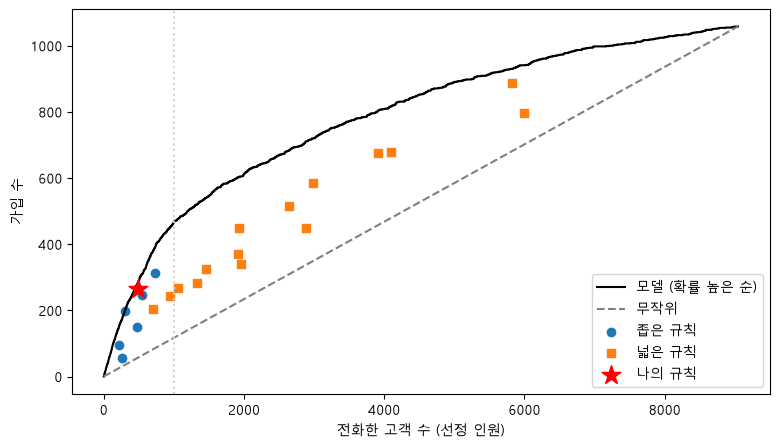

In [27]:
# [제공] 규칙들과 모델의 곡선
my_eff = rule_hits / cum_model[rule_n - 1]
print(f"효율 100% 이상(모델 이상)인 규칙: {(rules['효율'] >= 1).sum()}개 / {len(rules)}개")
print(f"나의 규칙 [{my_rule_text}] {rule_n:,}명 선정 → 가입 {rule_hits}명 | 모델 같은 인원 → 가입 {int(cum_model[rule_n - 1])}명 | 효율 {my_eff:.2f}")
print(f"  나보다 효율이 높은 규칙: {(rules['효율'] > my_eff).sum()}개")
print()
print("가족별 효율 중앙값:")
print(rules.groupby("가족")["효율"].median())
print()
print("선정 인원이 700~1,500명인 규칙 (1,000통 제약에 가까운 규칙)")
print(rules[rules["선정 인원"].between(700, 1500)].to_string(index=False))

x = np.arange(1, len(y_sorted) + 1)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x, cum_model, color="black", label="모델 (확률 높은 순)")
ax.plot(x, x * base_rate, linestyle="--", color="gray", label="무작위")
for family, marker in [("좁은 규칙", "o"), ("넓은 규칙", "s")]:
    part = rules[rules["가족"] == family]
    ax.scatter(part["선정 인원"], part["규칙 가입"], marker=marker, label=family)
ax.scatter([rule_n], [rule_hits], color="red", s=200, marker="*", zorder=5, label="나의 규칙")
ax.axvline(1000, color="lightgray", linestyle=":")
ax.set_xlabel("전화한 고객 수 (선정 인원)")
ax.set_ylabel("가입 수")
ax.legend(loc="lower right")
plt.show()

## 4-7. 결과를 본 뒤

> **[판단]** 예상 ①, ②는 맞았나요? 가장 크게 빗나간 것은 무엇이고, 왜 빗나갔다고 생각하나요?
>
> 나의 답: - 예상 ①은 **맞았습니다.** 효율 100% 이상인 규칙은 22개 중 **0개**입니다. 가장 가까운 것은 좁은 규칙 "이전 캠페인 성공"(306명, 효율 0.98)이었습니다.
> - 예상 ②도 **맞았습니다.** 효율 중앙값이 좁은 규칙 0.79, 넓은 규칙 0.63입니다.
>
> 가장 크게 빗나간 것은 넓은 규칙 **"휴대전화 연락" 하나만 쓴 규칙의 효율이 0.95로 2위**였다는 점입니다. 이 규칙은 5,820명이나 고릅니다. 인원이 이렇게 많으면 모델도 덜 유망한 고객까지 내려가야 해서, 모델의 장점이 줄어듭니다. 즉 **아주 많이 고르면 누가 골라도 결과가 비슷해집니다.** 하지만 이것은 1,000통 예산과는 상관없는 상황입니다.

> **[판단]** 좁은 규칙과 넓은 규칙의 효율은 어떻게 다른가요? 그림에서 두 가족의 점이 모델의 곡선과 얼마나 떨어져 있는지와 연결해 설명해 보세요. 넓은 규칙에 조건을 "그리고"로 더할수록 효율은 어떻게 변하나요?
>
> 나의 답: 좁은 규칙은 인원이 적고(200~700명) 가입률이 높아서, 점들이 모델 곡선 **가까이**에 있습니다(효율 중앙값 0.79). 넓은 규칙은 점들이 곡선보다 **훨씬 아래**에 있는 경우가 많습니다(중앙값 0.63).
> 넓은 규칙에 조건을 "그리고"로 더할수록 **효율이 떨어집니다.** 예를 들어 다음과 같습니다.
>
> | 규칙 | 선정 인원 | 효율 |
> | --- | --- | --- |
> | 휴대전화 연락 | 5,820명 | 0.95 |
> | + 주택 대출 없음 | 2,987명 | 0.81 |
> | + 통화 2회 이하 | 1,925명 | 0.74 |
> | + 잔액 1,000 이상 | 703명 | 0.54 |
>
> 조건을 더하면 인원은 줄지만 가입률은 조금씩만 오릅니다(15% → 29%). 같은 인원에서 모델은 정말 유망한 고객(가입률 50% 이상)을 골라내므로, 차이가 점점 벌어집니다.

> **[판단]** 1,000통 제약에 가까운 규칙(선정 700~1,500명)은 가입을 몇 명 얻나요? 같은 인원을 고른 모델과 비교하면 몇 배인가요? 마케팅팀이 규칙 대신 모델을 쓸 이유가 충분한가요?
>
> 나의 답: 선정 인원이 700~1,500명인 규칙 6개는 가입을 **205~325명** 얻습니다. 같은 인원을 고른 모델은 **379~540명**입니다.
>
> | 규칙 | 선정 인원 | 규칙 가입 | 모델 가입 | 모델/규칙 |
> | --- | --- | --- | --- | --- |
> | 이전 캠페인 성공 또는 60세 초과 또는 25세 이하 | 727명 | 312명 | 389명 | 약 1.25배 |
> | 휴대전화 연락 그리고 주택 대출 없음 그리고 잔액 1,000 이상 | 1,053명 | 269명 | 476명 | 약 1.77배 |
> | 주택 대출 없음 그리고 통화 2회 이하 그리고 잔액 1,000 이상 | 951명 | 244명 | 452명 | 약 1.85배 |
>
> 모델은 같은 인원에서 **1.25~1.85배** 가입을 얻습니다. 또 모델은 1,000명이든 2,000명이든 **원하는 인원에 정확히 맞출 수 있습니다.** 그래서 규칙 대신 모델을 쓸 이유는 충분합니다.

> **[판단]** 나의 규칙은 규칙들 사이에서 어디쯤인가요? 좁은 규칙과 넓은 규칙을 "또는"으로 합치면(예: 이전 캠페인 성공 또는 주택 대출 없음 그리고 잔액 1,000 이상) 선정 인원과 효율이 어떻게 될지 예상해 보세요. 이렇게 규칙을 손으로 조합해 가는 일과, 모델이 확률로 순서를 매기는 일은 무엇이 다른가요?
>
> 나의 답: 나의 규칙(효율 0.94)은 22개 중 **4위권**입니다. 나보다 효율이 높은 규칙은 3개뿐이지만, 고른 인원이 484명이라 1,000통을 채우지 못합니다.
> 좁은 규칙과 넓은 규칙을 "또는"으로 합치면 선정 인원은 두 규칙의 합에 가까워집니다(예: 306명 + 약 1,000명). 효율은 두 규칙의 중간쯤(약 0.6~0.8)이 될 것으로 예상합니다. 실제로 나의 넓힌 규칙(이전 성공 또는 60세 초과 또는 휴대전화·주택 대출 없음·좋은 달)은 1,017명에 430명, 효율 약 0.91이었습니다.
>
> 차이:
> - 규칙을 손으로 조합하는 일은 조건을 하나씩 바꿔 가며 **시행착오**로 맞추는 것입니다. 조합이 늘어날수록 평가용 데이터에 맞춰 고치게 될 위험도 커집니다.
> - 모델은 모든 피처를 **동시에, 적절한 무게로** 고려해 고객마다 확률을 매깁니다. 그래서 순서가 생기고, 원하는 인원에서 자르기만 하면 됩니다.

## 4-8. 마케팅팀 보고 메모

분석 결과를 마케팅팀장에게 메시지로 보낸다고 생각하고 쓰세요. 팀장은 머신러닝 용어를 모릅니다. 아래 네 가지가 모두 들어가야 합니다.

1. **누구에게 전화해야 하는가**: 선정 방식(예: 가입 가능성이 높은 순서대로 $N$명)을 한 문장으로 쓴다
2. **예산별 기대 가입**: 1,000통과 2,000통일 때 기대할 수 있는 가입 수를 쓰고, 현재 쓰는 방법(내 규칙)과 비교한다
3. **권고**: 몇 통을 걸 것을 권하는지, 4-4에서 가정한 비용 구조를 밝히고 이유를 쓴다
4. **주의할 점**: 통화 시간 열을 뺀 이유를 아직 확인하지 못했다는 것(Chapter 4 예고), 통화 수가 적은 집단 규칙의 불확실성, 이 데이터는 2008~2010년 포르투갈 은행의 것이라는 점

> **[판단]** 마케팅팀 보고 메모:
>
> 1. 선정 방식: 고객마다 **가입 가능성을 점수로 매기고, 점수가 높은 순서대로** 예산만큼(예: 1,000명) 전화합니다.
>
> 2. 예산별 기대 가입 (평가용 고객 9,043명 기준, 실제 고객 수와 비슷한 규모):
>    - **1,000통 → 약 468건** 가입 (무작위로 걸면 약 117건, 약 4배)
>    - **2,000통 → 약 611건** 가입
>    - 현재 방식(사람이 정한 규칙) "이전 캠페인 가입 고객 또는 60세 초과"는 484명만 골라 265건이고, 넓혀서 1,017명에 걸어도 430건입니다. 같은 인원이면 새 방식이 **약 40건 더** 얻습니다. 또 새 방식은 원하는 통화 수에 정확히 맞출 수 있습니다.
>
> 3. 권고와 이유: **통화 예산을 2,000통으로 늘리기를 권합니다.**
>    - 가정: 전화 1통 비용 10달러, 가입 1건의 가치 100달러 (실제 값이 아니라 가정입니다)
>    - 1,000통에서 2,000통으로 늘리면 가입이 143건 늘어납니다. 추가 비용 10,000달러보다 추가 가치 14,300달러가 커서 **약 4,300달러 이득**입니다.
>    - 3,000통까지는 본전을 겨우 넘고(이득 약 900달러), 그 이상은 손해입니다.
>
> 4. 주의할 점:
>    - 통화 시간 정보는 일부러 뺐습니다. 이 정보를 넣으면 점수가 크게 좋아지지만, 전화를 걸기 **전에는** 알 수 없는 정보일 수 있어 아직 쓸 수 있는지 확인하지 못했습니다(다음 분석에서 확인 예정).
>    - "3월에 전화한 고객" 같은 통화 수가 적은 집단의 높은 가입률은 우연이거나 당시 캠페인 방식 때문일 수 있어 믿기 어렵습니다.
>    - 이 데이터는 **2008~2010년 포르투갈 은행**의 것입니다. 금융위기 시기이고 나라도 달라서, 지금 우리 고객에게 그대로 맞지 않을 수 있습니다. 첫 캠페인에서 실제 결과를 확인하며 조정해야 합니다.
>
> 나의 답: 위 메모로 작성했습니다.

---
# 마무리

## 이 Chapter의 판단 포인트

> **놓친 가입 고객과 헛걸음한 전화 중 무엇이 더 비싼가? 임계값은 모델이 아니라 비용이 정한다.**

## 개인 검증 체크리스트에 추가

오늘 실습에서 내가 실제로 겪은 일을 바탕으로, 체크리스트의 줄을 내 말로 적으세요.

예: "분류 모델의 점수를 보면 임계값과 혼동행렬을 먼저 묻고, 같은 수를 고른 현행 규칙과 비교한다."

> **[판단]** 나의 체크리스트 4번(분류 모델의 점수를 볼 때):
>
> 나의 답: 분류 모델의 점수를 보면
> 1. "어떤 임계값에서의 숫자인가?"와 혼동행렬(놓친 가입·헛걸음)을 먼저 확인한다.
> 2. **같은 수의 고객을 고른** 현행 규칙과 비교한다.
> 3. 예산이 있으면 "상위 N명 중 몇 명을 얻는가"로 판단한다.

> **[판단]** 나의 체크리스트 5번(양성 비율이 낮은 문제에서 정확도를 볼 때):
>
> 나의 답: 양성 비율이 낮은 문제에서 정확도를 보면 먼저 **"전부 음성"이라고 답했을 때의 정확도**(이번에는 88.3%)와 비교한다. 정확도가 높아도 재현율·정밀도·상위 N명 성과를 함께 확인한다. (이번 모델은 정확도 89.3%였지만 재현율은 18.1%뿐이었다.)

## 제출물

- 이 노트북 (모든 **[판단]** 칸을 채운 상태)

수고했습니다. 다음 Chapter 4에서는 이번에 일부러 뺀 통화 시간 열을 넣으면 왜 점수가 갑자기 좋아지는지, 그리고 그 점수를 믿어도 되는지를 배웁니다.